# 03 - Geometry features: distance and angle to goal

**Day 3 (Alican):** compute two features for every shot:

| Column | Meaning | Unit |
|---|---|---|
| `x_m`, `y_m` | shot location on a 105 m x 68 m pitch | metres |
| `distance` | straight-line distance from the shot to the centre of the goal | metres |
| `angle` | angle between the lines from the shot to the two goal posts | radians |
| `angle_deg` | same angle in degrees (easier to read) | degrees |

The code lives in `src/features.py`. This notebook explains the formulas, **tests** them on
cases we can check by hand, and looks at how both features relate to scoring.

**Output:** `data/processed/shots_features.csv` (all 8,881 shots, `shot_type` kept).

Run the cells from top to bottom with the **`.venv`** kernel.

## 1. Setup

In [14]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path("..").resolve() / "src"))
from features import (GOAL_WIDTH, add_geometry_features, distance_to_goal, shot_angle,
                      shot_angle_cosine_rule, to_meters)
from eda_utils import draw_half_pitch, goal_rate_table, plot_goal_rate

FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})


def save(fig, name):
    """Save a figure into reports/figures."""
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


shots_all = pd.read_csv("../data/processed/shots_all.csv")
print(shots_all.shape)

(8881, 14)


## 2. Why not just use `100 - x`?
In notebook 02 we used `100 - start_x` as a quick distance. It has two problems:

1. **The axes have different units.** The pitch is 105 m long but only 68 m wide, so 1% on the
   x axis is 1.05 m and 1% on the y axis is 0.68 m.
2. **It ignores the sideways position.** Two shots with the same `x` are equally "far" by
   `100 - x`, even if one is in front of goal and the other is near the touchline.

Example: both shots below have `x = 88`, so `100 - x` says they are equally far.

In [15]:
example = pd.DataFrame({"start_x": [88, 88], "start_y": [50, 85]},
                       index=["central", "wide"])
example["100 - x"] = 100 - example["start_x"]
example = add_geometry_features(example)
example[["start_x", "start_y", "100 - x", "distance", "angle_deg"]].round(1)

,start_x,start_y,100 - x,distance,angle_deg
central,88,50,12,12.6,32.4
wide,88,85,12,26.9,7.4


The wide shot is about 2x further away and sees a much smaller part of the goal.
`100 - x` cannot tell them apart; `distance` and `angle` can.

## 3. The formulas

### Step 1 - percent to metres (`to_meters`)
We assume the standard pitch of 105 m x 68 m (real pitches vary a little; the data does not
give the real size, so this is the usual choice):

$$x_m = \frac{x}{100} \cdot 105 \qquad y_m = \frac{y}{100} \cdot 68$$

The goal is on the line $x_m = 105$, its centre at $y_m = 34$, and the posts at
$y_m = 34 \pm 3.66$ (the goal is 7.32 m wide).

### Step 2 - distance (`distance_to_goal`)
Pythagoras between the shot and the centre of the goal:

$$\text{distance} = \sqrt{(105 - x_m)^2 + (34 - y_m)^2}$$

### Step 3 - angle (`shot_angle`)
Draw a line from the shot to each post. The angle between the two lines tells us how
"wide" the goal looks from there. With $d_1$, $d_2$ the distances to the posts, the
**law of cosines** gives:

$$\cos(\theta) = \frac{d_1^2 + d_2^2 - 7.32^2}{2\, d_1 d_2}$$

In the code we compute the same angle with vectors, $\theta = \operatorname{atan2}(|a \times b|,\ a \cdot b)$,
where $a$ and $b$ point from the shot to the two posts. Both give the same number, but the
vector version never divides by zero and stays accurate right next to the goal line.
We check below that both versions agree.

How to read the angle:
- **large** (e.g. 40 deg+): close and central, the goal looks wide
- **small** (e.g. under 15 deg): far away or from a tight angle near the byline
- **0**: on the goal line outside the posts (the goal is invisible)
- **180 deg**: on the goal line between the posts

## 4. Tests on cases we can check by hand
Every `assert` stops the notebook with an error if the result is wrong. If this cell runs
without an error, all tests passed.

In [16]:
def close(a, b, tol=1e-6):
    return abs(float(a) - float(b)) < tol

# 1) Unit conversion: the centre of the goal line is (105 m, 34 m)
x_m, y_m = to_meters(100, 50)
assert close(x_m, 105) and close(y_m, 34)

# 2) Distance from the goal centre to itself is 0
assert close(distance_to_goal(105, 34), 0)

# 3) Real penalty spot: 11 m straight in front of goal
#    angle = 2 * atan(3.66 / 11) = 36.8 deg
assert close(distance_to_goal(94, 34), 11)
assert close(np.degrees(shot_angle(94, 34)), np.degrees(2 * np.arctan(3.66 / 11)))

# 4) Moving sideways at the same depth: further away and a smaller angle
assert distance_to_goal(94, 20) > distance_to_goal(94, 34)
assert shot_angle(94, 20) < shot_angle(94, 34)

# 5) On the goal line outside the posts the angle is 0,
#    on the goal line between the posts it is 180 deg
assert close(shot_angle(105, 10), 0)
assert close(np.degrees(shot_angle(105, 34)), 180)

# 6) Further away straight in front of goal -> smaller angle
assert shot_angle(75, 34) < shot_angle(94, 34)

print("All tests passed.")
print(f"Penalty spot (11 m): {np.degrees(shot_angle(94, 34)):.1f} deg")

All tests passed.
Penalty spot (11 m): 36.8 deg


## 5. Apply to the data

In [17]:
shots = add_geometry_features(shots_all)

# The vector formula and the law of cosines must give the same angle on every shot
diff = np.abs(shot_angle(shots["x_m"], shots["y_m"])
              - shot_angle_cosine_rule(shots["x_m"], shots["y_m"]))
print(f"Largest difference between the two angle formulas: {np.degrees(diff.max()):.2e} deg")

shots[["start_x", "start_y", "x_m", "y_m", "distance", "angle_deg", "shot_type", "is_goal"]].head()

Largest difference between the two angle formulas: 4.13e-13 deg


,start_x,start_y,x_m,y_m,distance,angle_deg,shot_type,is_goal
0,88,41,92.40,27.88,14.007655,26.770923,shot,True
1,85,52,89.25,35.36,15.808608,25.986925,shot,False
2,96,52,100.80,35.36,4.414703,78.788301,shot,True
3,81,33,85.05,22.44,23.057235,15.737204,shot,False
4,75,30,78.75,20.40,29.563872,12.585866,shot,False


### Sanity check on real data: penalties
In the data, penalties are recorded at about x = 90 (= 10.5 m), slightly closer than the real
11 m spot. So we expect a distance around 10.5 m and an angle around 38 deg.

In [18]:
shots.groupby("shot_type")[["distance", "angle_deg"]].describe().round(1)

distance                                          angle_deg  \
                  count  mean  std   min   25%   50%   75%   max     count   
shot_type                                                                    
free_kick_shot    350.0  27.9  5.9  17.9  24.6  27.5  30.4  80.9     350.0   
penalty            80.0  11.0  0.6   9.5  10.5  10.6  11.5  11.6      80.0   
shot             8451.0  18.3  8.0   1.3  12.2  17.0  24.6  67.7    8451.0   

                                                           
                mean   std   min   25%   50%   75%    max  
shot_type                                                  
free_kick_shot  13.8   3.5   1.0  12.1  13.9  15.3   23.2  
penalty         36.9   1.8  34.8  35.2  38.1  38.3   42.2  
shot            24.3  15.0   2.8  14.7  19.3  29.4  180.0

### Edge cases
The closest shots, the widest angles and the tightest angles. They should look physically possible.

In [19]:
cols = ["start_x", "start_y", "distance", "angle_deg", "is_goal", "shot_type"]
print("Closest shots:")
display(shots.nsmallest(3, "distance")[cols].round(2))
print("Widest angles:")
display(shots.nlargest(3, "angle_deg")[cols].round(2))
print("Tightest angles:")
display(shots.nsmallest(3, "angle_deg")[cols].round(2))

Closest shots:


,start_x,start_y,distance,angle_deg,is_goal,shot_type
6899,99,51,1.25,146.99,True,shot
8041,99,51,1.25,146.99,True,shot
209,99,52,1.72,143.65,True,shot


Widest angles:


,start_x,start_y,distance,angle_deg,is_goal,shot_type
1319,100,47,2.04,180.00,True,shot
6899,99,51,1.25,146.99,True,shot
8041,99,51,1.25,146.99,True,shot


Tightest angles:


,start_x,start_y,distance,angle_deg,is_goal,shot_type
8460,99,82,21.79,0.95,False,free_kick_shot
8825,97,12,26.03,1.99,False,free_kick_shot
1220,99,31,12.96,2.85,False,shot


**Interpretation:**
- **Penalties:** median 10.6 m and 38.1 deg (range 9.5-11.6 m, 35-42 deg). This matches the
  expected spot, so the conversion works on real data.
- **Closest shots:** about 1.3 m from goal with ~147 deg; all goals, as expected.
- **One shot has an angle of 180 deg:** it is recorded at x = 100 (on the goal line) between the
  posts. Physically possible (a tap-in on the line) and it was a goal, so we keep it.
- **Tightest angles (~1-3 deg):** shots from next to the byline, far to the side of the goal.

## 6. What does the angle look like on the pitch?
Each colour band is an area with the same angle. Close to goal and central = large angle.
The dashed lines show distance from the goal centre (10, 20, 30 m).

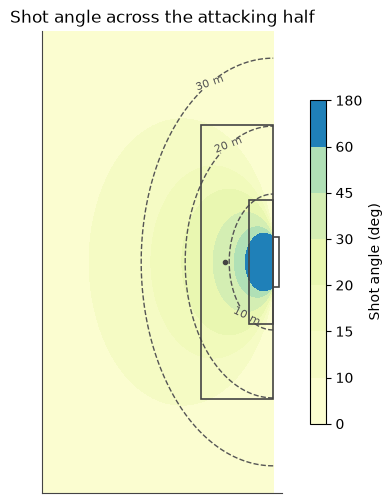

In [20]:
gx, gy = np.meshgrid(np.linspace(50, 100, 300), np.linspace(0, 100, 300))
grid_x_m, grid_y_m = to_meters(gx, gy)
grid_angle = np.degrees(shot_angle(grid_x_m, grid_y_m))
grid_dist = distance_to_goal(grid_x_m, grid_y_m)

fig, ax = plt.subplots(figsize=(7, 6))
cf = ax.contourf(gx, gy, grid_angle, levels=[0, 10, 15, 20, 30, 45, 60, 180],
                 cmap="YlGnBu", zorder=0)
cs = ax.contour(gx, gy, grid_dist, levels=[10, 20, 30], colors="#555555",
                linestyles="--", linewidths=1, zorder=1)
ax.clabel(cs, fmt="%d m", fontsize=8)
draw_half_pitch(ax)
fig.colorbar(cf, ax=ax, label="Shot angle (deg)", shrink=0.7)
ax.set_title("Shot angle across the attacking half")
save(fig, "10_angle_map.png")

Note that the plot is drawn in percentage coordinates, so the pitch looks square while the
distance circles look like ovals. In metres they are real circles.

## 7. Distributions (open-play shots)
From here on we use **open-play shots** only, for the same reasons as in notebook 02
(penalties and free kicks behave differently).

,distance,angle_deg
0.05,6.6,11.3
0.25,12.2,14.7
0.50,17.0,19.3
0.75,24.6,29.4
0.95,31.6,52.9


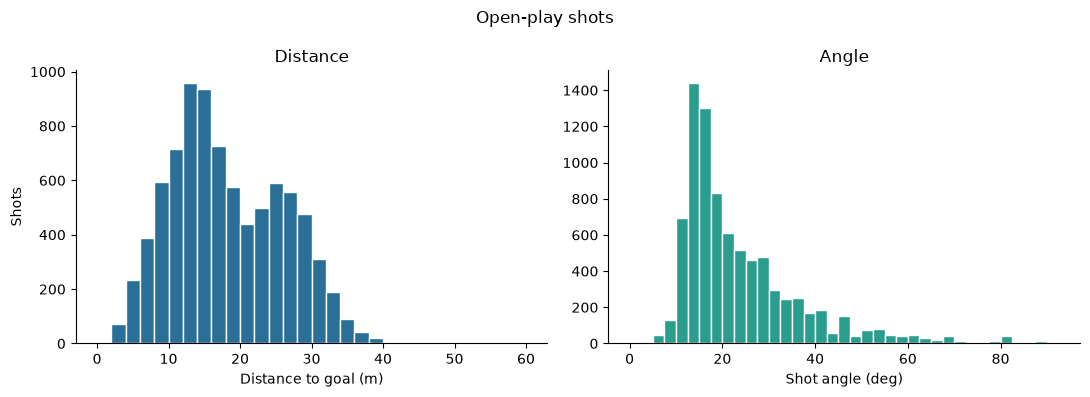

In [21]:
open_play = shots[shots["shot_type"] == "shot"].copy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.hist(open_play["distance"], bins=np.arange(0, 62, 2), color="#2a6f97", edgecolor="white")
ax1.set_xlabel("Distance to goal (m)")
ax1.set_ylabel("Shots")
ax1.set_title("Distance")
ax2.hist(open_play["angle_deg"], bins=np.arange(0, 95, 2.5), color="#2a9d8f", edgecolor="white")
ax2.set_xlabel("Shot angle (deg)")
ax2.set_title("Angle")
fig.suptitle("Open-play shots")
fig.tight_layout()
save(fig, "11_distance_angle_hist.png")

open_play[["distance", "angle_deg"]].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(1)

**Interpretation:** the median open-play shot is taken from **17.0 m** with an angle of **19.3 deg**.
Half of the shots are between 12 and 25 m. The angle has a long right tail: a few shots from very
close (above 50 deg) and most shots between 15 and 30 deg. A handful of angles above 90 deg are
not shown (shots almost on the goal line).

## 8. Goal rate by distance and by angle (open play)
Same style as notebook 02: bars are the goal rate, black lines are 95% confidence intervals,
`n` is the number of shots.

,shots,goals,goal_rate,ci_low,ci_high
distance_bin,,,,,
"[0, 6)",310,156,0.503,0.448,0.559
"[6, 11)",1325,290,0.219,0.197,0.242
"[11, 16)",2266,286,0.126,0.113,0.141
"[16, 20)",1304,99,0.076,0.063,0.092
"[20, 25)",1214,38,0.031,0.023,0.043
"[25, 30)",1345,29,0.022,0.015,0.031
"[30, 100)",687,16,0.023,0.014,0.037


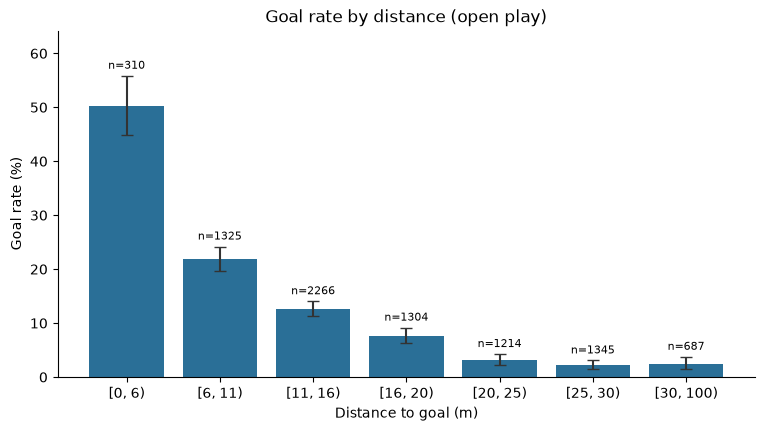

In [22]:
open_play["distance_bin"] = pd.cut(open_play["distance"], [0, 6, 11, 16, 20, 25, 30, 100], right=False)
dist_table = goal_rate_table(open_play, "distance_bin")
display(dist_table.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_goal_rate(ax, dist_table, title="Goal rate by distance (open play)", xlabel="Distance to goal (m)")
save(fig, "12_goal_rate_distance_m.png")

,shots,goals,goal_rate,ci_low,ci_high
angle_bin,,,,,
"[0, 10)",185,9,0.049,0.026,0.090
"[10, 15)",2133,60,0.028,0.022,0.036
"[15, 20)",2132,108,0.051,0.042,0.061
"[20, 30)",2065,254,0.123,0.110,0.138
"[30, 45)",1212,218,0.180,0.159,0.202
"[45, 180)",723,264,0.365,0.331,0.401


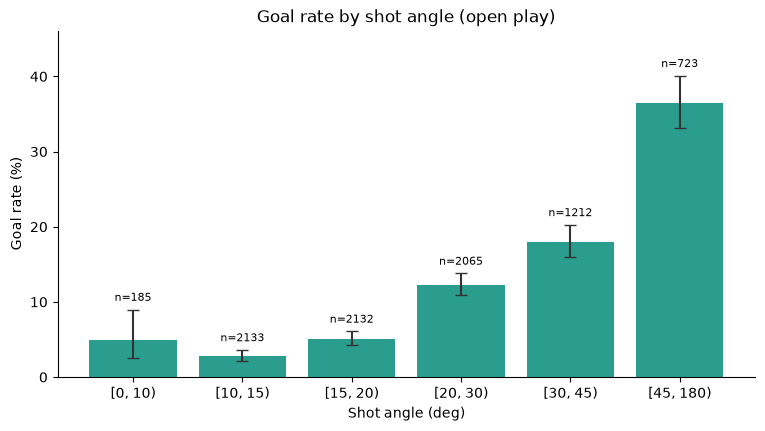

In [23]:
open_play["angle_bin"] = pd.cut(open_play["angle_deg"], [0, 10, 15, 20, 30, 45, 180], right=False)
angle_table = goal_rate_table(open_play, "angle_bin")
display(angle_table.round(3))

fig, ax = plt.subplots(figsize=(9, 4.5))
plot_goal_rate(ax, angle_table, title="Goal rate by shot angle (open play)", xlabel="Shot angle (deg)",
               color="#2a9d8f")
save(fig, "13_goal_rate_angle.png")

**Interpretation:**
- **Distance:** the goal rate halves roughly every 5 m: **50.3%** under 6 m, 21.9% at 6-11 m,
  12.6% at 11-16 m, 7.6% at 16-20 m, then about 2-3% from 20 m and beyond.
  This is a much sharper picture than the percentage-based plot in notebook 02.
- **Angle:** the goal rate rises with the angle, from about 3% (10-15 deg) to **36.5%** above 45 deg.
- The first angle bin (under 10 deg, 4.9%) looks higher than 10-15 deg (2.8%), but it has only
  185 shots and 9 goals and the confidence intervals overlap, so this is most likely noise.

## 9. Distance and angle together
The two features are related: further away usually means a smaller angle. If they carried the
same information, we would only need one of them in the model.

Correlation distance vs angle: Pearson -0.745, Spearman -0.886


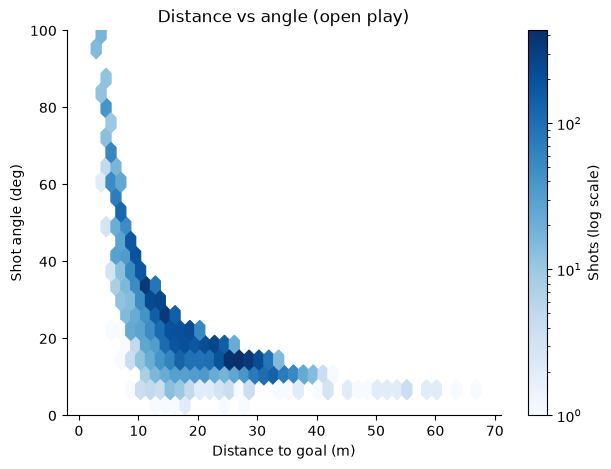

In [24]:
pearson = open_play[["distance", "angle"]].corr().iloc[0, 1]
spearman = open_play[["distance", "angle"]].corr(method="spearman").iloc[0, 1]
print(f"Correlation distance vs angle: Pearson {pearson:.3f}, Spearman {spearman:.3f}")

fig, ax = plt.subplots(figsize=(7, 5))
hb = ax.hexbin(open_play["distance"], open_play["angle_deg"], gridsize=40, cmap="Blues",
               mincnt=1, bins="log")
fig.colorbar(hb, ax=ax, label="Shots (log scale)")
ax.set_xlabel("Distance to goal (m)")
ax.set_ylabel("Shot angle (deg)")
ax.set_ylim(0, 100)
ax.set_title("Distance vs angle (open play)")
save(fig, "14_distance_vs_angle.png")

The correlation is strong (Pearson -0.75, Spearman -0.89), so the features overlap a lot.
But do they still add something on their own? We compare shots **at the same distance**
with different angles. Cells with fewer than 30 shots are hidden because their rate is not reliable.

angle_group,"[0, 15)","[15, 20)","[20, 30)","[30, 180)"
distance_group,,,,
"[0, 11)",NaN,NaN,20.5,28.3
"[11, 16)",9.1,10.1,12.7,14.9
"[16, 20)",5.2,7.0,9.2,NaN
"[20, 25)",2.4,3.4,NaN,NaN
"[25, 100)",2.1,2.5,NaN,NaN


angle_group,"[0, 15)","[15, 20)","[20, 30)","[30, 180)"
distance_group,,,,
"[0, 11)",14,10,166,1444
"[11, 16)",154,286,1335,491
"[16, 20)",233,530,541,0
"[20, 25)",289,902,23,0
"[25, 100)",1628,404,0,0


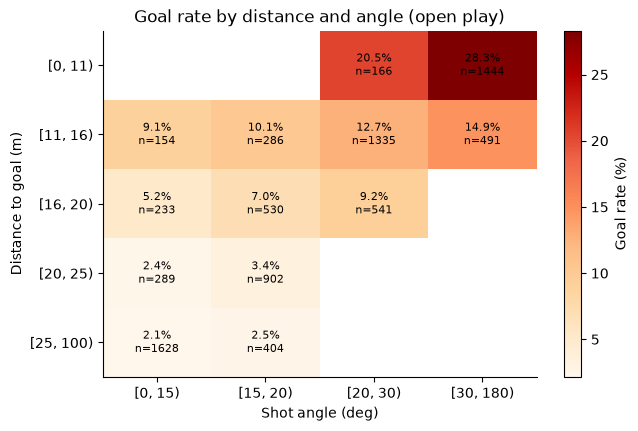

In [25]:
open_play["distance_group"] = pd.cut(open_play["distance"], [0, 11, 16, 20, 25, 100], right=False)
open_play["angle_group"] = pd.cut(open_play["angle_deg"], [0, 15, 20, 30, 180], right=False)

rate = open_play.pivot_table(index="distance_group", columns="angle_group", values="is_goal",
                             aggfunc="mean", observed=False)
count = open_play.pivot_table(index="distance_group", columns="angle_group", values="is_goal",
                              aggfunc="size", observed=False)
rate_reliable = rate.where(count >= 30)

display((rate_reliable * 100).round(1))
display(count)

fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(rate_reliable * 100, cmap="OrRd", aspect="auto")
ax.set_xticks(range(len(rate.columns)), [str(c) for c in rate.columns])
ax.set_yticks(range(len(rate.index)), [str(i) for i in rate.index])
for i in range(rate.shape[0]):
    for j in range(rate.shape[1]):
        n = count.iloc[i, j]
        if n >= 30:
            ax.text(j, i, f"{rate.iloc[i, j] * 100:.1f}%\nn={n}", ha="center", va="center", fontsize=8)
ax.set_xlabel("Shot angle (deg)")
ax.set_ylabel("Distance to goal (m)")
ax.set_title("Goal rate by distance and angle (open play)")
fig.colorbar(im, ax=ax, label="Goal rate (%)")
save(fig, "15_goal_rate_distance_angle.png")

**Interpretation:**
- **At the same distance, a wider angle still scores more.** Under 11 m: 20.5% (20-30 deg) vs
  28.3% (30 deg+). At 11-16 m: 9.1% -> 10.1% -> 12.7% -> 14.9%. At 16-20 m: 5.2% -> 7.0% -> 9.2%.
- So **angle adds information that distance alone does not have** (it captures how central the
  shot is), even though the two are strongly correlated.
- Empty cells are mostly geometrically impossible combinations (you cannot be 25 m away and see
  the goal at 30 deg+), not missing data.
- **For Day 4:** use both features in the logistic regression, but remember they are correlated.
  Their individual coefficients can be unstable and harder to interpret; we should look at them
  together, not one by one.

## 10. Save

In [26]:
OUT_PATH = Path("..") / "data" / "processed" / "shots_features.csv"
shots.to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH.resolve(), "|", shots.shape)
print(list(shots.columns))

Saved: /Users/alicanaksel/Desktop/xG-Analyzer/xG-Analyzer/data/processed/shots_features.csv | (8881, 19)
['playerId', 'matchId', 'teamId', 'matchPeriod', 'eventSec', 'id', 'start_x', 'start_y', 'is_goal', 'left_foot', 'right_foot', 'header', 'counter_attack', 'shot_type', 'x_m', 'y_m', 'distance', 'angle', 'angle_deg']


You can create the same file without the notebook by running, from the project root:

```bash
python src/features.py
```

## 11. Summary for the team
- **New file:** `data/processed/shots_features.csv` = `shots_all.csv` + `x_m`, `y_m`, `distance`,
  `angle`, `angle_deg`. All shot types are kept; filter with `shot_type` when modelling.
- **Formulas are tested** on hand-checked cases (penalty spot = 11 m / 36.8 deg, goal line = 0 / 180 deg),
  and two independent angle formulas agree on every shot.
- **Distance** is the strongest single pattern (50% under 6 m, ~2% beyond 20 m).
- **Angle** adds information on top of distance (at the same distance a wider angle scores more).
- **Distance and angle are strongly correlated** (Spearman -0.89). Keep this in mind when reading
  the Day 4 logistic regression coefficients.
- **Next (Day 4):** train/test split (Veli) and logistic regression with `distance`, `angle`,
  `header`, `counter_attack` (Ali), on open-play shots.